# ****Student Health Risk Prediction using Artificial Neural Networks (ANN)****


# **Problem Type**

Multi-class Classification

# **Business Problem**

Educational institutions often face challenges in identifying students who are at risk of developing health problems due to factors such as poor sleep habits, unhealthy eating patterns, lack of physical activity, excessive screen time, high stress levels, and academic pressure. Delayed identification of health risks can negatively affect students academic performance, attendance, and overall well-being. Manual monitoring is time-consuming and often identifies problems only after they become severe.

# **Problem Statement**
The primary objective of this project is to support early health risk prediction, encourage preventive healthcare, and contribute to improved student well-being. By providing timely and accurate predictions, reducing future health complications, and creating a healthier academic environment.

## -> Predict student health risk accurately. 
## -> Identify at-risk students early. 
## -> Support healthcare and counseling decisions. 
## -> Improve student well-being and academic outcomes.

# **Data Understanding**

### **ID:** Unique identifier assigned to each student for record identification; it does not contribute to predicting health condition.
### **Sleep Duration:** Represents the average number of hours a student sleeps each day.
### **Heart Rate:** Indicates the student's resting heart rate, measured in beats per minute (BPM).
### **BMI:** Body Mass Index, which measures whether a student's weight is appropriate for their height.
### **Calorie Expenditure:** Represents the total number of calories burned through daily activities and exercise.
### **Step Count:** Indicates the total number of steps the student takes in a day, reflecting daily physical movement.
### **Exercise Duration:** Represents the amount of time the student spends exercising each day, usually measured in minutes.
### **Water Intake:** Indicates the average amount of water consumed by the student each day.
### **Diet Type:** Describes the student's dietary pattern or eating habits, such as healthy, balanced, or unhealthy.
### **Stress Level:** Represents the student's level of stress, typically categorized as low, medium, or high.
### **Sleep Quality:** Indicates how restful and uninterrupted the student's sleep is.
### **Physical Activity Level:** Represents the overall intensity of the student's daily physical activities, such as low, moderate, or high.
### **Smoking/Alcohol:** Indicates whether the student has smoking or alcohol consumption habits that may affect health.
### **Gender:** Represents the biological gender of the student.
### **Health Condition (Target Variable):** Represents the student's overall health status (e.g., Healthy, At-risk, or Unhealthy), which is the variable to be predicted by the model.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

In [3]:
df=pd.read_csv(r"/kaggle/input/datasets/pravallikabaddam/studenthealthriskprediction/train.csv")
df

,id,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,3,unhealthy,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,4,at-risk,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
690083,690083,at-risk,6.31,69.7,24.11,2157.0,NaN,30.8,3.00,non-veg,high,poor,active,yes,female
690084,690084,at-risk,5.78,54.0,26.36,2858.0,6488.0,52.4,1.46,veg,medium,average,moderate,no,male
690085,690085,fit,7.64,85.7,21.91,2195.0,9241.0,41.3,1.57,non-veg,NaN,average,active,no,male
690086,690086,at-risk,6.74,73.0,18.73,2061.0,13366.0,56.6,2.60,balanced,NaN,average,active,yes,male


In [4]:
df = df.iloc[:300000]

In [5]:
df.shape

(300000, 15)

In [6]:
df.dtypes

id                           int64
health_condition            object
sleep_duration             float64
heart_rate                 float64
bmi                        float64
calorie_expenditure        float64
step_count                 float64
exercise_duration          float64
water_intake               float64
diet_type                   object
stress_level                object
sleep_quality               object
physical_activity_level     object
smoking_alcohol             object
gender                      object
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       300000 non-null  int64  
 1   health_condition         300000 non-null  object 
 2   sleep_duration           266960 non-null  float64
 3   heart_rate               296565 non-null  float64
 4   bmi                      293955 non-null  float64
 5   calorie_expenditure      276982 non-null  float64
 6   step_count               294035 non-null  float64
 7   exercise_duration        297018 non-null  float64
 8   water_intake             281004 non-null  float64
 9   diet_type                296997 non-null  object 
 10  stress_level             263929 non-null  object 
 11  sleep_quality            274572 non-null  object 
 12  physical_activity_level  283989 non-null  object 
 13  smoking_alcohol          287539 non-null  object 
 14  gend

In [8]:
df.isna().sum()

id                             0
health_condition               0
sleep_duration             33040
heart_rate                  3435
bmi                         6045
calorie_expenditure        23018
step_count                  5965
exercise_duration           2982
water_intake               18996
diet_type                   3003
stress_level               36071
sleep_quality              25428
physical_activity_level    16011
smoking_alcohol            12461
gender                      9212
dtype: int64

In [9]:
missing_percent = (df.isna().sum() / len(df)) * 100
print(missing_percent)

id                          0.000000
health_condition            0.000000
sleep_duration             11.013333
heart_rate                  1.145000
bmi                         2.015000
calorie_expenditure         7.672667
step_count                  1.988333
exercise_duration           0.994000
water_intake                6.332000
diet_type                   1.001000
stress_level               12.023667
sleep_quality               8.476000
physical_activity_level     5.337000
smoking_alcohol             4.153667
gender                      3.070667
dtype: float64


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,id,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake
count,300000.000000,266960.000000,296565.000000,293955.000000,276982.000000,294035.000000,297018.000000,281004.000000
mean,149999.500000,6.993564,75.102047,22.986749,2226.122575,8620.910817,38.771944,2.187720
std,86602.684716,1.217345,8.179483,2.482694,347.773348,3931.080590,14.757924,0.518549
min,0.000000,3.000000,50.000000,16.000000,1200.000000,1002.000000,0.000000,0.500000
25%,74999.750000,6.150000,69.400000,21.320000,2053.000000,5391.000000,29.200000,1.840000
50%,149999.500000,6.990000,75.100000,23.000000,2240.000000,8861.000000,39.400000,2.170000
75%,224999.250000,7.820000,80.700000,24.660000,2456.000000,12119.000000,49.400000,2.500000
max,299999.000000,10.000000,107.700000,34.820000,3580.000000,14999.000000,99.800000,4.720000


In [12]:
df.describe(include=["object"])

,health_condition,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
count,300000,296997,263929,274572,283989,287539,290788
unique,3,3,3,3,3,3,3
top,at-risk,veg,medium,average,sedentary,yes,male
freq,257553,100269,113770,93122,95577,97187,103385


In [13]:
df.corr(numeric_only=True)

,id,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake
id,1.000000,-0.001011,-0.001388,0.000249,-0.001620,0.001792,-0.000220,0.002003
sleep_duration,-0.001011,1.000000,-0.006682,-0.073996,-0.004735,0.003072,0.001229,0.001117
heart_rate,-0.001388,-0.006682,1.000000,0.000348,-0.005113,-0.005656,-0.003543,0.001604
bmi,0.000249,-0.073996,0.000348,1.000000,0.115933,-0.022517,-0.022854,0.000425
calorie_expenditure,-0.001620,-0.004735,-0.005113,0.115933,1.000000,0.399747,0.393502,-0.000918
step_count,0.001792,0.003072,-0.005656,-0.022517,0.399747,1.000000,0.438434,-0.000298
exercise_duration,-0.000220,0.001229,-0.003543,-0.022854,0.393502,0.438434,1.000000,0.002907
water_intake,0.002003,0.001117,0.001604,0.000425,-0.000918,-0.000298,0.002907,1.000000


In [14]:
df.head()

,id,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,3,unhealthy,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,4,at-risk,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male


In [15]:
df.columns

Index(['id', 'health_condition', 'sleep_duration', 'heart_rate', 'bmi',
       'calorie_expenditure', 'step_count', 'exercise_duration',
       'water_intake', 'diet_type', 'stress_level', 'sleep_quality',
       'physical_activity_level', 'smoking_alcohol', 'gender'],
      dtype='object')

# splitting the data into input,target features

In [16]:
x=df.drop(columns=["id","health_condition"],axis=1)
y=df["health_condition"]

In [17]:
y.head()

0    unhealthy
1      at-risk
2    unhealthy
3    unhealthy
4      at-risk
Name: health_condition, dtype: object

In [18]:
for i in df.columns:
      print(df[i].unique())

[     0      1      2 ... 299997 299998 299999]
['unhealthy' 'at-risk' 'fit']
[ 5.22  5.53  5.29  4.7   7.23  5.11  8.21  7.47  5.94  6.97   nan  8.64
  7.02  5.66  8.58  7.09  8.38  7.71  7.35  7.17  6.39  7.12  4.57  7.8
  6.05  6.47  5.84  5.83  6.22  6.79  5.75  5.73  6.01  4.77  5.06  5.99
  8.    7.25  6.65  8.08  6.42  7.26  8.77  7.15  5.59  6.95  7.45  8.35
  6.16  6.14  7.3   8.26  8.13  6.4   6.07  6.32  7.48  7.11  7.24  8.86
  7.27  9.98  6.1   7.5   7.94  7.72  7.74  6.56  4.84  9.01  5.18  6.34
  6.57  8.12  3.88  6.68  7.43  5.82  5.71  6.83  9.    5.34  7.78  8.42
  5.91  9.3   7.1   8.68  7.57  7.4   8.14  6.82  7.18  6.52  5.65  7.64
  8.9   7.87  7.84  6.29  9.92  8.2   9.75  5.67  6.41  9.03  4.71  7.88
  6.38  8.28  7.6   6.24  5.49  8.69  8.45  8.41  7.13  6.7   6.53  6.17
  7.19  8.51  7.34  6.03  7.58  8.37  8.19  5.57  6.48  8.24  5.46  8.96
  6.62  9.28  6.64  6.37  6.75  7.59  6.76  8.02  7.07  7.65  7.22  5.69
  9.47  8.55  7.    6.98  4.91  5.97  7.08  9.4

# Seggregating data into numerical and categorical columns

In [19]:
num_cols=['sleep_duration','heart_rate','bmi','calorie_expenditure','step_count','exercise_duration','water_intake']
nominal_cols=['diet_type','smoking_alcohol','gender']
ord_cols=['stress_level','sleep_quality','physical_activity_level']

In [20]:
order=[["low","medium","high"],['poor','average','good'],['sedentary','moderate','active']]

In [21]:
df[num_cols].skew()

sleep_duration        -0.007392
heart_rate             0.003224
bmi                    0.019940
calorie_expenditure   -0.182240
step_count            -0.182469
exercise_duration     -0.375119
water_intake           0.110822
dtype: float64

# Data Preparation

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,LabelEncoder

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [24]:
num_pipeline=Pipeline([("numerical_imputation",SimpleImputer(strategy="mean")),("scaling",StandardScaler())])
nominal_pipeline=Pipeline([("nominal_imputation",SimpleImputer(strategy="most_frequent")),("nominal_encoding",OneHotEncoder(handle_unknown="ignore",drop="first"))])
ordinal_pipeline=Pipeline([("ordinal_imputation",SimpleImputer(strategy="most_frequent")),("ordinal_encoding",OrdinalEncoder(categories=order))])

In [25]:
preprocessing=ColumnTransformer([("numerical_pipeline",num_pipeline,num_cols),
                                          ("categorical_pipeline",nominal_pipeline,nominal_cols),
                                          ("ordinal_pipeline",ordinal_pipeline,ord_cols)])
preprocessing

ColumnTransformer(transformers=[('numerical_pipeline',
                                 Pipeline(steps=[('numerical_imputation',
                                                  SimpleImputer()),
                                                 ('scaling',
                                                  StandardScaler())]),
                                 ['sleep_duration', 'heart_rate', 'bmi',
                                  'calorie_expenditure', 'step_count',
                                  'exercise_duration', 'water_intake']),
                                ('categorical_pipeline',
                                 Pipeline(steps=[('nominal_imputation',
                                                  SimpleImputer(strategy='most_frequent...
                                                                handle_unknown='ignore'))]),
                                 ['diet_type', 'smoking_alcohol', 'gender']),
                                ('ordinal_pipeline',
                                 Pipeline(steps=[('ordinal_imputation',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ordinal_encoding',
                                                  OrdinalEncoder(categories=[['low',
                                                                              'medium',
                                                                              'high'],
                                                                             ['poor',
                                                                              'average',
                                                                              'good'],
                                                                             ['sedentary',
                                                                              'moderate',
                                                                              'active']]))]),
                                 ['stress_level', 'sleep_quality',
                                  'physical_activity_level'])])

In [26]:
X=preprocessing.fit_transform(x)
X

array([[-1.54444251, -0.5535866 ,  1.08777124, ...,  2.        ,
         1.        ,  0.        ],
       [-1.27449054, -0.46751228,  1.16101495, ...,  0.        ,
         1.        ,  1.        ],
       [-1.48348561,  0.0366373 ,  0.63203265, ...,  2.        ,
         0.        ,  2.        ],
       ...,
       [ 1.1463691 , -0.22158565,  0.69306907, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.37134569,  0.56537955, -0.03529887, ...,  1.        ,
         1.        ,  2.        ],
       [-0.54300777, -0.41832695,  0.71341454, ...,  1.        ,
         2.        ,  2.        ]])

In [27]:
le=LabelEncoder()
Y=le.fit_transform(y)

In [28]:
Y

array([2, 0, 2, ..., 0, 0, 0])

In [29]:
x.shape,y.shape,X.shape,Y.shape

((300000, 13), (300000,), (300000, 16), (300000,))

# splitting the data into train_test

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=23)

In [32]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((240000, 16), (60000, 16), (240000,), (60000,))

In [33]:
print(type(x_train))
print(type(x_test))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [34]:
X

array([[-1.54444251, -0.5535866 ,  1.08777124, ...,  2.        ,
         1.        ,  0.        ],
       [-1.27449054, -0.46751228,  1.16101495, ...,  0.        ,
         1.        ,  1.        ],
       [-1.48348561,  0.0366373 ,  0.63203265, ...,  2.        ,
         0.        ,  2.        ],
       ...,
       [ 1.1463691 , -0.22158565,  0.69306907, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.37134569,  0.56537955, -0.03529887, ...,  1.        ,
         1.        ,  2.        ],
       [-0.54300777, -0.41832695,  0.71341454, ...,  1.        ,
         2.        ,  2.        ]])

# Architecture Building

In [35]:
from keras.models import Sequential
from tensorflow.keras.layers import Input,Dense

In [36]:
X.shape[1]

16

In [37]:
X

array([[-1.54444251, -0.5535866 ,  1.08777124, ...,  2.        ,
         1.        ,  0.        ],
       [-1.27449054, -0.46751228,  1.16101495, ...,  0.        ,
         1.        ,  1.        ],
       [-1.48348561,  0.0366373 ,  0.63203265, ...,  2.        ,
         0.        ,  2.        ],
       ...,
       [ 1.1463691 , -0.22158565,  0.69306907, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.37134569,  0.56537955, -0.03529887, ...,  1.        ,
         1.        ,  2.        ],
       [-0.54300777, -0.41832695,  0.71341454, ...,  1.        ,
         2.        ,  2.        ]])

In [38]:
print(X.shape)
print(Y.shape)
print(type(Y))

(300000, 16)
(300000,)
<class 'numpy.ndarray'>


In [39]:
model=Sequential()

model.add(Input(shape=(X.shape[1],)))
model.add(Dense(units=36,activation="relu"))

model.add(Dense(units=3,activation="softmax"))

2026-08-10 09:37:14.022433: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [40]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 36)             │           612 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           111 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 723 (2.82 KB)

 Trainable params: 723 (2.82 KB)

 Non-trainable params: 0 (0.00 B)

# Compilation

In [41]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

# Model Training

In [42]:
model.fit(x_train,y_train,epochs=10,validation_data=(x_test,y_test),batch_size=50)

Epoch 1/10
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.9403 - loss: 0.2089 - val_accuracy: 0.9558 - val_loss: 0.1702
Epoch 2/10
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9585 - loss: 0.1615 - val_accuracy: 0.9580 - val_loss: 0.1578
Epoch 3/10
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9610 - loss: 0.1522 - val_accuracy: 0.9600 - val_loss: 0.1491
Epoch 4/10
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9628 - loss: 0.1458 - val_accuracy: 0.9615 - val_loss: 0.1456
Epoch 5/10
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9632 - loss: 0.1420 - val_accuracy: 0.9620 - val_loss: 0.1437
Epoch 6/10
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9636 - loss: 0.1395 - val_accuracy: 0.9623 - val_loss: 0.1409
Epoch 7/10
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9637 - loss: 0.1376 - val_accuracy: 0.9626 - val_loss: 0.1394
Epoch 8/10
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9640 - loss: 0

# Identification of model(overfit,underfit,best fit)

<Axes: >

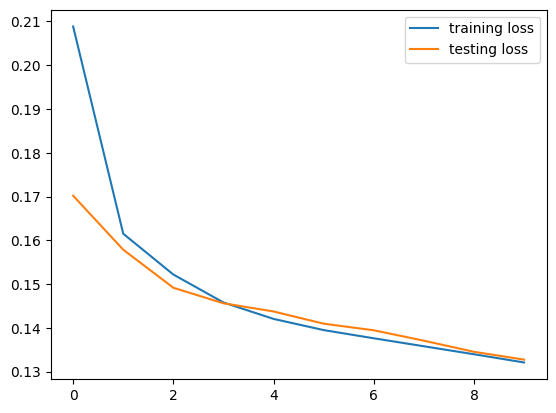

In [43]:
sns.lineplot(x=model.history.epoch,y=model.history.history['loss'],label='training loss')
sns.lineplot(x=model.history.epoch,y=model.history.history['val_loss'],label='testing loss')

# Evaluation

In [44]:
from sklearn.metrics import classification_report

In [45]:
y_pred=model.predict(x_test)
y_pred

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


array([[9.87332523e-01, 6.67405408e-03, 5.99338766e-03],
       [8.61930549e-01, 6.83028577e-03, 1.31239146e-01],
       [9.90961850e-01, 1.26435619e-03, 7.77382497e-03],
       ...,
       [9.88723457e-01, 9.83427186e-03, 1.44219468e-03],
       [9.99885261e-01, 1.47857945e-05, 9.98777759e-05],
       [6.12232194e-04, 2.61697405e-05, 9.99361575e-01]], dtype=float32)

In [46]:
y_pred = np.argmax(y_pred,axis=1)
y_pred

array([0, 0, 0, ..., 0, 0, 2])

In [47]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.96      0.99      0.98     51553
           1       0.91      0.81      0.86      3411
           2       0.97      0.76      0.85      5036

    accuracy                           0.96     60000
   macro avg       0.95      0.85      0.90     60000
weighted avg       0.96      0.96      0.96     60000



# checking for Balanced or Unbalanced data

In [48]:
y.value_counts()

health_condition
at-risk      257553
unhealthy     25085
fit           17362
Name: count, dtype: int64

# creating class weights 

In [49]:
from sklearn.utils import compute_class_weight

In [50]:
class_weight=compute_class_weight(class_weight="balanced",classes=np.unique(y_train),y=y_train)
dict_class={i:class_weight[i] for i in range(len(class_weight))}
dict_class

{0: np.float64(0.3883495145631068),
 1: np.float64(5.734355960146226),
 2: np.float64(3.9902239513192677)}

# Hyperparameter tuning

## Bayesian Optuna

In [51]:
import optuna 
from keras.layers import Dropout
from keras.optimizers import SGD,Adagrad,RMSprop,Adam
from keras.layers import BatchNormalization

## Creating Objective

In [52]:
from tensorflow.keras.callbacks import EarlyStopping

In [53]:
def objective(trail):
    n_layers=trail.suggest_int('n_layers',1,6)
    epochs=trail.suggest_int('epochs',1,100)
    learn_rate=trail.suggest_float('learning rate',1e-4,1e-2,log=True)
    batch_size=trail.suggest_int('batch_size',6,128)
    activation=trail.suggest_categorical('activation',["sigmoid","tanh","relu"])
    optimizers=trail.suggest_categorical('optimizers',['SGD','Adagrad','RMSprop','Adam'])

    model=Sequential()
    model.add(Input(shape=(x_train.shape[1],)))

    for i in range(n_layers):

        n_units=trail.suggest_int(f'units{i}',1,100)
        strength=trail.suggest_float(f'regularization{i}',1e-5,1e-2,log=True)
    
        dropout=trail.suggest_float(f'dropout{i}',0.1,0.5)
        
        model.add(Dense(units=n_units,activation=activation))
        model.add(BatchNormalization())
    
    model.add(Dense(3,activation='softmax'))
    print("--------------------------------------------------------------------------")
   # print(np.unique(y_train))
   # print(np.unique(y_test))
    

    if optimizers=='SGD':
        optimizer=SGD(learning_rate=learn_rate)
    elif optimizers=='Adagrad':
        optimizer=Adagrad(learning_rate=learn_rate)
    elif optimizers=='RMSprop':
        optimizer=RMSprop(learning_rate=learn_rate)
    else:
        optimizer=Adam(learning_rate=learn_rate)
        
    early_stopping=EarlyStopping(monitor="val_loss",patience=5,min_delta=0.001,restore_best_weights=True)
        
    model.compile(optimizer=optimizers,loss='sparse_categorical_crossentropy',metrics=['accuracy'])

    model.fit(x_train,y_train,epochs=epochs,batch_size=batch_size,validation_data=(x_test,y_test),callbacks=[early_stopping],class_weight=dict_class,verbose=0)

    return max(model.history.history['val_accuracy'])

## Creating a study

In [54]:
study=optuna.create_study(direction="maximize")

[I 2026-08-10 09:39:01,032] A new study created in memory with name: no-name-ae3f8a61-d523-43db-8a3f-8ddb36251f34


In [55]:
study.optimize(objective,n_trials=2)

--------------------------------------------------------------------------


[I 2026-08-10 09:40:02,153] Trial 0 finished with value: 0.89205002784729 and parameters: {'n_layers': 1, 'epochs': 51, 'learning rate': 0.0011177686972455919, 'batch_size': 71, 'activation': 'relu', 'optimizers': 'RMSprop', 'units0': 65, 'regularization0': 0.002350141766819014, 'dropout0': 0.4452485423735689}. Best is trial 0 with value: 0.89205002784729.


--------------------------------------------------------------------------


[I 2026-08-10 09:40:54,870] Trial 1 finished with value: 0.8991166949272156 and parameters: {'n_layers': 5, 'epochs': 42, 'learning rate': 0.002162168078288775, 'batch_size': 119, 'activation': 'sigmoid', 'optimizers': 'RMSprop', 'units0': 26, 'regularization0': 7.072421794974965e-05, 'dropout0': 0.2576872501068962, 'units1': 67, 'regularization1': 9.432303240998466e-05, 'dropout1': 0.47462373339424324, 'units2': 52, 'regularization2': 0.003180627380487391, 'dropout2': 0.45806521944956724, 'units3': 19, 'regularization3': 0.0019193222969090089, 'dropout3': 0.4583169701215374, 'units4': 75, 'regularization4': 0.0006255472505196843, 'dropout4': 0.4478559721297045}. Best is trial 1 with value: 0.8991166949272156.


In [56]:
study.best_params

{'n_layers': 5,
 'epochs': 42,
 'learning rate': 0.002162168078288775,
 'batch_size': 119,
 'activation': 'sigmoid',
 'optimizers': 'RMSprop',
 'units0': 26,
 'regularization0': 7.072421794974965e-05,
 'dropout0': 0.2576872501068962,
 'units1': 67,
 'regularization1': 9.432303240998466e-05,
 'dropout1': 0.47462373339424324,
 'units2': 52,
 'regularization2': 0.003180627380487391,
 'dropout2': 0.45806521944956724,
 'units3': 19,
 'regularization3': 0.0019193222969090089,
 'dropout3': 0.4583169701215374,
 'units4': 75,
 'regularization4': 0.0006255472505196843,
 'dropout4': 0.4478559721297045}

# Rebuilding the architecture with optimal parameters

In [57]:
from keras.optimizers import Adam
from keras.losses import SparseCategoricalCrossentropy

In [58]:
from keras.initializers import HeNormal
from keras.layers import Dropout
from tensorflow.keras.regularizers import L1L2

In [59]:
model_f=Sequential()

model_f.add(Input(shape=(x_train.shape[1],)))

model_f.add(Dense(units=41,activation="relu",kernel_initializer=HeNormal(),kernel_regularizer=L1L2(l1=0.004819,l2=0.004819)))
model_f.add(Dropout(rate=0.2))
model_f.add(BatchNormalization(momentum=0.3))
model_f.add(Dense(units=38,activation="relu",kernel_initializer=HeNormal(),kernel_regularizer=L1L2(l1=0.000125,l2=0.000125)))
model_f.add(Dropout(rate=0.1))
model_f.add(BatchNormalization(momentum=0.3))
model_f.add(Dense(units=50,activation="relu",kernel_initializer=HeNormal(),kernel_regularizer=L1L2(l1=0.000132,l2=0.000132)))
model_f.add(Dropout(rate=0.2))
model_f.add(BatchNormalization(momentum=0.3))
model_f.add(Dense(units=58,activation="relu",kernel_initializer=HeNormal(),kernel_regularizer=L1L2(l1=0.000812,l2=0.000812)))
model_f.add(Dropout(rate=0.3))
model_f.add(BatchNormalization(momentum=0.3))
model_f.add(Dense(units=37,activation="relu",kernel_initializer=HeNormal(),kernel_regularizer=L1L2(l1=0.000010,l2=0.000010)))
model_f.add(Dropout(rate=0.3))
model_f.add(BatchNormalization(momentum=0.3))



model_f.add(Dense(units=3,activation="softmax"))

In [60]:
model_f.compile(optimizer=Adam(learning_rate=0.0002),loss=SparseCategoricalCrossentropy(),metrics=["accuracy"])

In [61]:
print(x_train.shape)
print(y_train.shape)

(240000, 16)
(240000,)


In [62]:
model_f.fit(x_train,y_train,epochs=14,validation_data=(x_test,y_test),batch_size=11,class_weight=dict_class,verbose=True)

Epoch 1/14
21819/21819 ━━━━━━━━━━━━━━━━━━━━ 102s 4ms/step - accuracy: 0.5025 - loss: 2.1256 - val_accuracy: 0.3140 - val_loss: 19.7516
Epoch 2/14
21819/21819 ━━━━━━━━━━━━━━━━━━━━ 97s 4ms/step - accuracy: 0.6766 - loss: 0.9552 - val_accuracy: 0.1771 - val_loss: 23.4137
Epoch 3/14
21819/21819 ━━━━━━━━━━━━━━━━━━━━ 97s 4ms/step - accuracy: 0.7507 - loss: 0.6716 - val_accuracy: 0.8264 - val_loss: 1.4016
Epoch 4/14
21819/21819 ━━━━━━━━━━━━━━━━━━━━ 94s 4ms/step - accuracy: 0.7910 - loss: 0.5822 - val_accuracy: 0.6698 - val_loss: 5.3882
Epoch 5/14
21819/21819 ━━━━━━━━━━━━━━━━━━━━ 94s 4ms/step - accuracy: 0.8128 - loss: 0.5292 - val_accuracy: 0.8468 - val_loss: 0.8146
Epoch 6/14
21819/21819 ━━━━━━━━━━━━━━━━━━━━ 93s 4ms/step - accuracy: 0.8234 - loss: 0.5050 - val_accuracy: 0.2226 - val_loss: 6.4162
Epoch 7/14
21819/21819 ━━━━━━━━━━━━━━━━━━━━ 93s 4ms/step - accuracy: 0.8266 - loss: 0.4917 - val_accuracy: 0.3048 - val_loss: 8.4808
Epoch 8/14
21819/21819 ━━━━━━━━━━━━━━━━━━━━ 90s 4ms/step - accurac

In [63]:
ypred=model.predict(x_test)
ypred

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


array([[9.87332523e-01, 6.67405408e-03, 5.99338766e-03],
       [8.61930549e-01, 6.83028577e-03, 1.31239146e-01],
       [9.90961850e-01, 1.26435619e-03, 7.77382497e-03],
       ...,
       [9.88723457e-01, 9.83427186e-03, 1.44219468e-03],
       [9.99885261e-01, 1.47857945e-05, 9.98777759e-05],
       [6.12232194e-04, 2.61697405e-05, 9.99361575e-01]], dtype=float32)

In [64]:
predicted_classes = np.argmax(ypred, axis=1)
predicted_classes


array([0, 0, 0, ..., 0, 0, 2])

In [65]:
print(classification_report(y_test,predicted_classes,target_names=["fit","unhealthy","at-risk"]))

              precision    recall  f1-score   support

         fit       0.96      0.99      0.98     51553
   unhealthy       0.91      0.81      0.86      3411
     at-risk       0.97      0.76      0.85      5036

    accuracy                           0.96     60000
   macro avg       0.95      0.85      0.90     60000
weighted avg       0.96      0.96      0.96     60000



In [66]:
test_data=pd.read_csv(r'/kaggle/input/datasets/pravallikabaddam/ttest-data/test.csv')
test_data.head()

,id,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,690088,5.35,64.9,23.48,2745.0,14167.0,59.5,1.86,veg,high,poor,active,occasional,male
1,690089,NaN,83.1,22.42,1773.0,6801.0,24.5,2.40,balanced,high,poor,sedentary,yes,other
2,690090,6.68,59.7,24.14,3040.0,13250.0,48.5,2.76,balanced,medium,poor,active,no,NaN
3,690091,7.13,78.5,26.26,2494.0,6331.0,56.9,2.34,veg,low,good,moderate,yes,other
4,690092,5.49,77.7,23.29,1828.0,13894.0,39.4,2.45,veg,high,average,active,occasional,other


In [67]:
test_data.dtypes

id                           int64
sleep_duration             float64
heart_rate                 float64
bmi                        float64
calorie_expenditure        float64
step_count                 float64
exercise_duration          float64
water_intake               float64
diet_type                   object
stress_level                object
sleep_quality               object
physical_activity_level     object
smoking_alcohol             object
gender                      object
dtype: object

In [68]:
result=model_f.predict(x_test)
result

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step


array([[9.9999779e-01, 1.6760246e-06, 5.2341767e-07],
       [6.5129817e-01, 9.8896483e-03, 3.3881226e-01],
       [9.9975872e-01, 1.5566828e-04, 8.5646752e-05],
       ...,
       [9.9997705e-01, 1.9997136e-05, 2.9107996e-06],
       [9.9999875e-01, 9.7108409e-07, 1.9165779e-07],
       [0.0000000e+00, 5.4092778e-27, 9.9999994e-01]], dtype=float32)

In [69]:
test_data=pd.read_csv(r'/kaggle/input/datasets/pravallikabaddam/ttest-data/test.csv')
test_data

,id,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,690088,5.35,64.9,23.48,2745.0,14167.0,59.5,1.86,veg,high,poor,active,occasional,male
1,690089,NaN,83.1,22.42,1773.0,6801.0,24.5,2.40,balanced,high,poor,sedentary,yes,other
2,690090,6.68,59.7,24.14,3040.0,13250.0,48.5,2.76,balanced,medium,poor,active,no,NaN
3,690091,7.13,78.5,26.26,2494.0,6331.0,56.9,2.34,veg,low,good,moderate,yes,other
4,690092,5.49,77.7,23.29,1828.0,13894.0,39.4,2.45,veg,high,average,active,occasional,other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295748,985836,7.13,77.5,22.20,2221.0,13981.0,65.6,2.17,balanced,low,average,active,occasional,other
295749,985837,6.25,69.5,20.93,2242.0,2370.0,23.6,1.98,balanced,NaN,average,moderate,yes,female
295750,985838,NaN,77.0,23.62,2111.0,7647.0,25.1,2.18,veg,high,average,sedentary,no,other
295751,985839,7.25,66.3,21.47,2009.0,4672.0,25.1,2.02,veg,high,poor,moderate,no,female


In [70]:
preprocessed_test_data=preprocessing.transform(test_data)
preprocessed_test_data

array([[-1.43123684, -1.25447748,  0.20070861, ...,  2.        ,
         0.        ,  2.        ],
       [ 0.        ,  0.98345481, -0.23061542, ...,  2.        ,
         0.        ,  0.        ],
       [-0.27305579, -1.89388671,  0.46926886, ...,  1.        ,
         0.        ,  2.        ],
       ...,
       [ 0.        ,  0.2333786 ,  0.25767594, ...,  2.        ,
         1.        ,  0.        ],
       [ 0.22330751, -1.08232884, -0.61717941, ...,  2.        ,
         0.        ,  1.        ],
       [-2.07563833,  1.22938144,  0.32685055, ...,  2.        ,
         1.        ,  2.        ]])

In [71]:
results=model_f.predict(preprocessed_test_data)
results

9243/9243 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step


array([[0.0000000e+00, 1.5931297e-18, 9.9999994e-01],
       [7.9542649e-01, 5.4442822e-03, 1.9912916e-01],
       [5.6362391e-01, 4.2922565e-01, 7.1504745e-03],
       ...,
       [9.5992684e-01, 3.0519853e-03, 3.7021130e-02],
       [9.6057487e-01, 3.2968977e-03, 3.6128148e-02],
       [0.0000000e+00, 7.2013467e-26, 1.0000000e+00]], dtype=float32)

In [72]:
output=np.argmax(results,axis=1)
output

array([2, 0, 0, ..., 0, 0, 2])

In [73]:
output = pd.Series(output).map({
    1: "fit",
    2: "unhealthy",
    0: "at-risk"
})

In [74]:
output

0         unhealthy
1           at-risk
2           at-risk
3           at-risk
4         unhealthy
            ...    
295748          fit
295749      at-risk
295750      at-risk
295751      at-risk
295752    unhealthy
Length: 295753, dtype: object

In [75]:
df_submission=pd.DataFrame({"id":test_data["id"],"health_condition":output})
df_submission

,id,health_condition
0,690088,unhealthy
1,690089,at-risk
2,690090,at-risk
3,690091,at-risk
4,690092,unhealthy
...,...,...
295748,985836,fit
295749,985837,at-risk
295750,985838,at-risk
295751,985839,at-risk


In [76]:
import pickle
with open(r"C:\Users\PRAVALLIKA\Downloads\playground-series-s6e7\preprocessor1.pkl","wb") as f:
     pickle.dump(preprocessing,f)

In [77]:
model_f.save(r"C:\Users\PRAVALLIKA\Downloads\playground-series-s6e7\Architecture1.keras")

In [78]:
from keras.models import load_model
Deployment=load_model(r"C:\Users\PRAVALLIKA\Downloads\playground-series-s6e7\Architecture1.keras")

In [79]:
x.head()

,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male


In [80]:
X[0]

array([-1.54444251, -0.5535866 ,  1.08777124, -0.15597867, -1.87443287,
       -1.29198226, -0.65300726,  0.        ,  1.        ,  0.        ,
        1.        ,  0.        ,  0.        ,  2.        ,  1.        ,
        0.        ])

In [81]:
input_df = pd.DataFrame(X[0],)

In [82]:
input_df

,0
0,-1.544443
1,-0.553587
2,1.087771
3,-0.155979
4,-1.874433
5,-1.291982
6,-0.653007
7,0.000000
8,1.000000
9,0.000000


In [83]:
x.shape,y.shape,X.shape,Y.shape,x_train.shape,x_test.shape,y_train.shape,y_test.shape

((300000, 13),
 (300000,),
 (300000, 16),
 (300000,),
 (240000, 16),
 (60000, 16),
 (240000,),
 (60000,))

In [84]:
x.columns

Index(['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure',
       'step_count', 'exercise_duration', 'water_intake', 'diet_type',
       'stress_level', 'sleep_quality', 'physical_activity_level',
       'smoking_alcohol', 'gender'],
      dtype='object')

# **Challenges**
### **1. Challenge:** The dataset was highly imbalanced, leading to biased predictions toward the  
###   majority class.
### **Solution:** Applied Class Weights during ANN training to improve minority class prediction.

### **2. Challenge:** Selecting the optimal ANN architecture (hidden layers, neurons, dropout,etc.
### was difficult.
### **Solution:** Used Optuna Hyperparameter Tuning to identify the best model configuration.


# **Conclusion**

The Student Health Risk Prediction system successfully demonstrates the application of 
Artificial Neural Networks (ANN) in predicting students' health risk based on health, 
lifestyle, and academic factors. By following the CRISP-ML(Q) methodology,the project achieved 
96% prediction accuracy through effective data preprocessing, feature engineering, 
hyperparameter optimization, and model evaluation. The Streamlit-based application provides 
real-time health risk assessment, enabling early identification of at-risk students. This 
project highlights the potential of AI in supporting preventive healthcare and prom# oting 
healthier lifestyles through timely, data-driven decision-making.
